# Practical Exercise — Introduction to Deep Generative Models
**Arthur SATOUF**  
## TP 1.1 — Autoencoders on Fashion MNIST

For each practical exercise (TP), please work in groups of two or three. Create a **private GitHub repository** and add **arthur-75**.

> Complete the `xxx` placeholders and answer the questions. Existing starter code and guidance follow the original PDF; example outputs are not provided as solutions.

Use pytorch documentation https://docs.pytorch.org/docs/2.14/index.html to solve.

### Goals
- Load and visualize Fashion MNIST.
- Build a convolutional autoencoder.
- Train and evaluate the model.
- Extract and visualize latent-space embeddings.
- Reconstruct images and generate new ones.

## 1. Load and Visualize the Dataset
### 1.1 Import Necessary Libraries
Before implementation, import the required libraries.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

**Question:** What transformations might be useful when working with images?

*Your answer: Normaliser les pixels, réduire la taille des images si elles sont trop grande, faire en sorte que tous les images aient le même format.

### 1.2 Prepare the Data
- Load Fashion MNIST (`train=True` for training and `train=False` for validation).
- Pad images from 28 × 28 to 32 × 32.
- Convert images to tensors.
- Use `DataLoader` for mini-batch processing.

In [20]:
# Preprocessing
transform = transforms.Compose([
    transforms.Resize(32),  # Pad 28x28 images to 32x32
    transforms.ToTensor()  # Convert images to tensors
])
batch_size = 16

In [21]:
# Load data
train_dataset = datasets.FashionMNIST(root="./data", train=True, transform=transform, download=True)
train_loader = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle=False)
val_dataset = datasets.FashionMNIST(root="./data", train=False, transform=transform, download=True)
val_loader = DataLoader(dataset=val_dataset,batch_size=batch_size , shuffle=False)

### 1.3 Visualizing Sample Images
- Extract a batch of images and labels.
- Display images in a grid.
- Use Matplotlib to plot grayscale images.

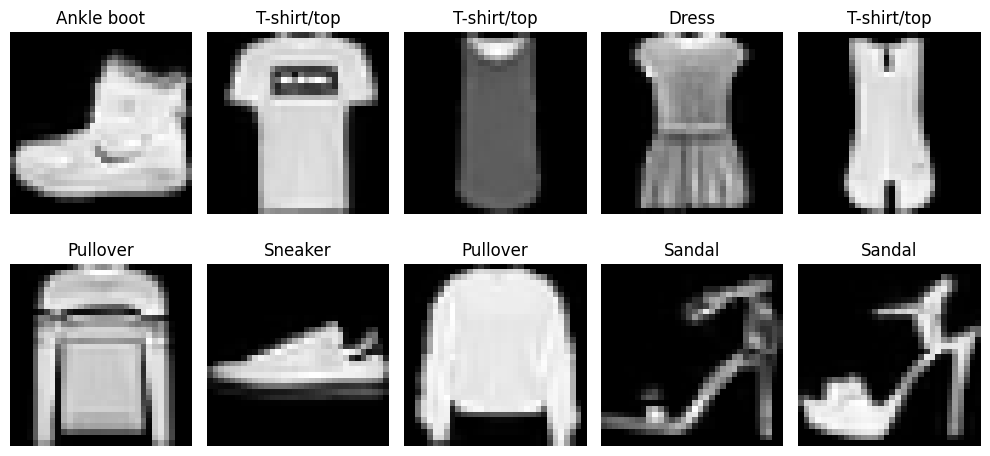

In [26]:
class_labels = {
    0: 'T-shirt/top', 1: 'Trouser', 2: 'Pullover', 3: 'Dress', 4: 'Coat',
    5: 'Sandal', 6: 'Shirt', 7: 'Sneaker', 8: 'Bag', 9: 'Ankle boot'
}

def plot_sample_images(loader):
    data_iter = iter(loader)
    images, labels = next(data_iter)
    images = images.numpy()

    plt.figure(figsize=(10, 5))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(images[i].squeeze(), cmap="gray")
        plt.title(class_labels[labels[i].item()])
        plt.axis("off")
    plt.tight_layout()
    plt.show()

plot_sample_images(train_loader)

## 2. Build the Autoencoder
An autoencoder consists of:
1. **Encoder:** Reduces an image to a compressed representation (latent space).
2. **Decoder:** Reconstructs the image from its compressed representation.

### 2.1 Define the Autoencoder Model
Use convolutional layers in the encoder and transposed convolutions in the decoder.

### 2.2 Define the Latent Space
Flatten the encoder output, then use a fully connected layer to compress it to **N dimensions**. For this exercise, use **N = 2** for visualization (other applications may use larger dimensions).

**Questions**
- How does reducing dimensionality help the model?
- What happens when the latent space is too small or too large?

*Your answers:*
- Réduire les dimensions permet de facilité les calculs.
-  Si il est trop petits on arrivera pas a recré l'image qu'on souhaite, s'il est trop grand on risque de tomber sur une image qu'on ne veut pas.

In [79]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# Define the Autoencoder Model
class Autoencoder(nn.Module):
    def __init__(self, input_shape=(1, 32, 32), latent_dim=2):
        """
        Initialize the Autoencoder model.
        - input_shape: (1, 32, 32) for grayscale images.
        - latent_dim: Number of neurons in the latent space.
        """
        super(Autoencoder,self).__init__()

        # Encoder
        self.encoder = nn.Sequential(
            # First convolutional layer: 1 channel -> 32 feature maps
            nn.Conv2d(in_channels=1, out_channels=32, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),  # Activation function

            # Second convolutional layer
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),  # Activation function

            # Third convolutional layer
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),  # TODO: Conv2d with 128 filters, kernel_size=3, stride=2, padding=1
            nn.Sigmoid()  # Activation function
        )

        # Dynamically calculate the flattened size after encoding
        flattened_size, decode_shape = self.calculate_flattened_size(self.encoder, input_shape)

        # Latent space
        self.fc = nn.Sequential(
            nn.Flatten(start_dim=1),  # Flatten encoded features
            nn.Linear(flattened_size, latent_dim)  # Latent dimension
        )

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, flattened_size),  # Latent space -> feature map
            nn.Unflatten(decode_shape[0], decode_shape[1:]),

            # Transposed convolution layers
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),  # Activation

            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1),  # TODO: ConvTranspose2d, 64 -> 32 channels, k=3, stride=2, padding=1, output_padding=1
            nn.ReLU(),  # Activation

            # Final layer: single-channel grayscale output
            nn.ConvTranspose2d(32, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()  # TODO: Activation; output should be between 0 and 1
        )

    def calculate_flattened_size(self, model, input_shape):
        """Return the flattened encoder size and output shape."""
        with torch.no_grad():
            dummy_input = torch.zeros(1, *input_shape)
            output = model(dummy_input)
            return output.numel(), output.shape

    def forward(self, x):
        """Return the reconstructed image and latent representation."""
        x = self.encoder(x)  # Encoder
        latent = self.fc(x)
        x = self.decoder(latent)  # Decoder
        return x, latent

### Test dimension consistency

In [80]:
x_sample = torch.randn(1, 1, 32, 32)
model_test = Autoencoder()
image_test, latent_space = model_test(x_sample)
assert image_test.shape == x_sample.shape, "Output dimensions do not match input dimensions!"

## 3. Train the Autoencoder
### 3.1 Define the Training Process
- Choose an optimizer (e.g., Adam, learning rate 0.0001) and a reconstruction loss (e.g., MSE).
- Iterate over epochs and mini-batches.
- Move images to the selected CPU/GPU device.
- Forward pass, compute the loss, backpropagate, and update weights.

### 3.2 Evaluate the Model
- Disable gradients using `torch.no_grad()`.
- Run reconstruction on validation images.
- Calculate validation loss and binary cross-entropy.

In [81]:
from tqdm import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def train_model(model, train_loader, val_loader, epochs):
    """Train the autoencoder."""
    model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=0.0001)
    loss_fn = nn.MSELoss()

    print("Start Training...")
    train_losses = []
    val_losses = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0
        tqdm_loader = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}")

        for x, _ in tqdm_loader:
            x = x.to(device)
            recon_x, _ = model(x)
            # TODO: Compute reconstruction MSE between recon_x and x
            loss = loss_fn(recon_x, x)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            tqdm_loader.set_postfix(loss=loss.item())

        avg_train_loss = total_loss / len(train_loader.dataset)
        avg_val_loss, ce_losss = evaluate_model(model, val_loader)
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        print(f"Epoch [{epoch + 1}/{epochs}], Train Loss: {100*avg_train_loss:.6f} %, "
              f"Val Loss: {100*avg_val_loss:.6f} %, "
              f"Val Loss cross_entropy: {100*ce_losss:.6f} %")

    plot_training_loss(train_losses, val_losses)

In [82]:
def evaluate_model(model, loader):
    """Evaluate the autoencoder on validation data."""
    model.eval()
    total_loss = 0
    loss_fn = nn.MSELoss()  # Same loss function as training
    ce_losss = 0
    with torch.no_grad():
        for x, _ in tqdm(loader, desc="Evaluating"):
            x = x.to(device)
            recon_x, _ = model(x)
            loss = loss_fn(recon_x, x)  # TODO: Compute loss between recon_x and x
            ce_loss = F.binary_cross_entropy(recon_x, x)
            total_loss += loss.item()
            ce_losss += ce_loss

    avg_loss = total_loss / len(loader.dataset)
    ce_losss /= len(loader.dataset)
    return avg_loss, ce_losss

def plot_training_loss(train_losses, val_losses):
    """Plot the training and validation losses."""
    plt.figure(figsize=(8, 5))
    plt.plot(train_losses, label="Training Loss", marker="o")
    plt.plot(val_losses, label="Validation Loss", marker="s")
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend()
    plt.grid()
    plt.show()

Start Training...


Evaluating: 100%|██████████| 625/625 [00:08<00:00, 76.89it/s]


Epoch [1/2], Train Loss: 0.258209 %, Val Loss: 0.187307 %, Val Loss cross_entropy: 2.296145 %


Evaluating: 100%|██████████| 625/625 [00:08<00:00, 69.91it/s]


Epoch [2/2], Train Loss: 0.179313 %, Val Loss: 0.172865 %, Val Loss cross_entropy: 2.238498 %


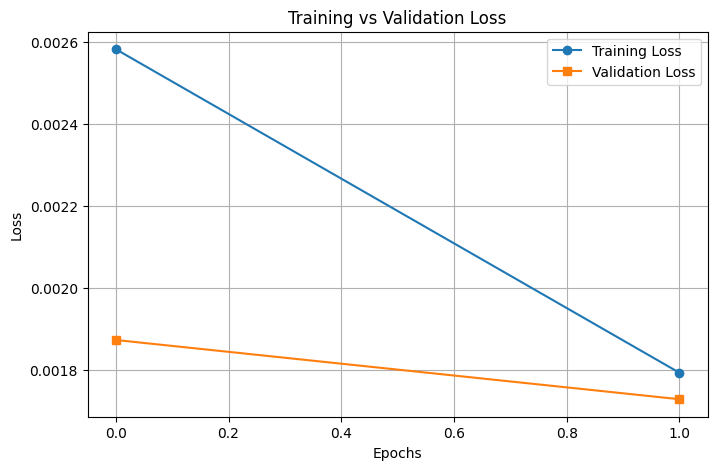

In [83]:
# Instantiate and train the model
autoencoder = Autoencoder()
train_model(autoencoder, train_loader, val_loader, epochs=2)

## 4. Reconstruct Images Using the Autoencoder
### 4.1 Extract a Few Test Images
- Select a validation batch.
- Pass it through the autoencoder and retrieve reconstructions.

### 4.2 Compare Original and Reconstructed Images
- Plot originals on top and reconstructions on the bottom.
- Observe the differences.

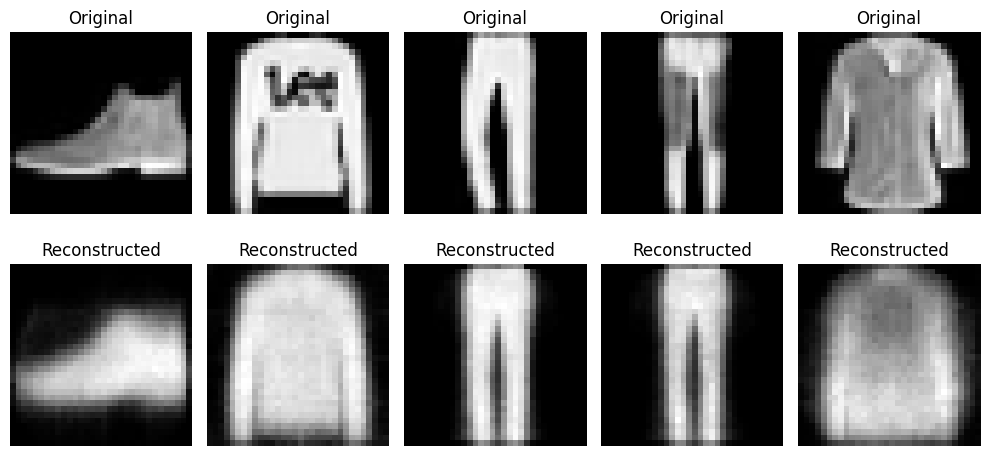

In [84]:
def plot_reconstructions(model, loader, ex=True):
    model.eval()
    model = model.to("cpu")

    with torch.no_grad():
        if ex:
            for x, _ in loader:
                recon_x, _ = model(x)
                break
        else:
            x = loader
            recon_x = model.decoder(x)

    x = x.cpu().numpy()
    recon_x = recon_x.cpu().numpy()

    plt.figure(figsize=(10, 5))
    for i in range(5):
        if ex:
            plt.subplot(2, 5, i + 1)
            plt.imshow(x[i].squeeze(), cmap="gray")
            plt.title("Original")
            plt.axis("off")

        plt.subplot(2, 5, i + 6)
        plt.imshow(recon_x[i].squeeze(), cmap="gray")
        plt.title("Reconstructed")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

plot_reconstructions(autoencoder, val_loader)

**Question:** How could you improve the model to get sharper images?

*Your answer:* Mettre une meilleure valeur pour la latent_space.

## 5. Visualize the Latent Space
### 5.1 Extract Embeddings
- Pass training images through the encoder.
- Store latent representations and labels.

In [85]:
embeddings = []
labels = []

autoencoder = autoencoder.to(device)
with torch.no_grad():
    for x, y in train_loader:
        x = x.to(device)
        _, latent = autoencoder.forward(x) # TODO: Call the autoencoder and extract embeddings
        embeddings.append(latent.cpu().numpy())
        labels.append(y.numpy())

embeddings = np.concatenate(embeddings, axis=0)
labels = np.concatenate(labels, axis=0)
unique_labels = np.unique(labels)
autoencoder = autoencoder.to("cpu")

### 5.2 Plot in a 2D Space
- For a two-dimensional latent space, plot points in a scatter plot.
- Assign separate colors to the clothing categories.

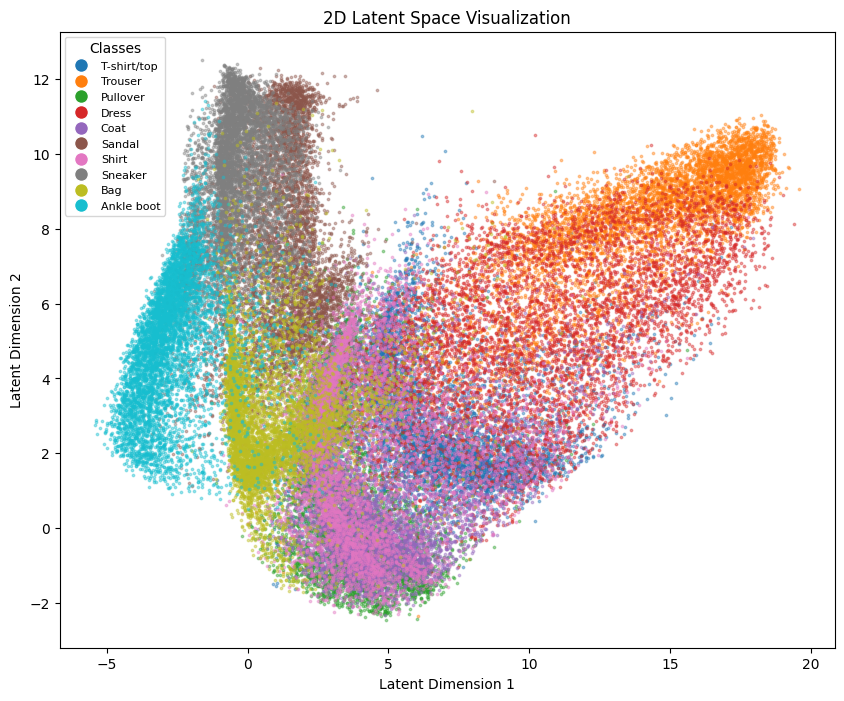

In [86]:
# Plot the 2D embeddings
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

plt.figure(figsize=(10, 8))
legend_handles = []
for i, label in enumerate(unique_labels):
    indices = np.where(labels == label)[0]
    scatter = plt.scatter(
        embeddings[indices, 0], embeddings[indices, 1],
        c=[colors[i]], alpha=0.4, s=3, label=class_labels[label]
    )
    legend_handles.append(
        Line2D([0], [0], marker='o', color='w', label=f'{class_labels[label]}',
               markersize=10, markerfacecolor=colors[i])
    )

plt.xlabel('Latent Dimension 1')
plt.ylabel('Latent Dimension 2')
plt.title('2D Latent Space Visualization')
plt.legend(handles=legend_handles, title='Classes', loc='upper left', fontsize=8)
plt.show()

**Question:** Would images of similar clothing types cluster together, and are they well represented?

*Your answer:* Les sacs et les pulls on des représentation similaire, on peut supposer car c'est oarce qu'ils ont une forme similaire.

## 6. Generate New Images Using the Decoder
### 6.1 Sample Random Points in Latent Space
- Pick random latent vectors within the range of existing embeddings.
- Pass the vectors through the decoder.

### 6.2 Plot Generated Images
- Display decoder outputs.
- Observe how varying latent vectors changes the generated images.

Generated Latent Samples:
 tensor([[10.5810, -1.3701],
        [ 6.3282,  9.2763],
        [14.8997,  2.8582],
        [16.7020,  0.7815],
        [ 1.7403, 11.6755]])


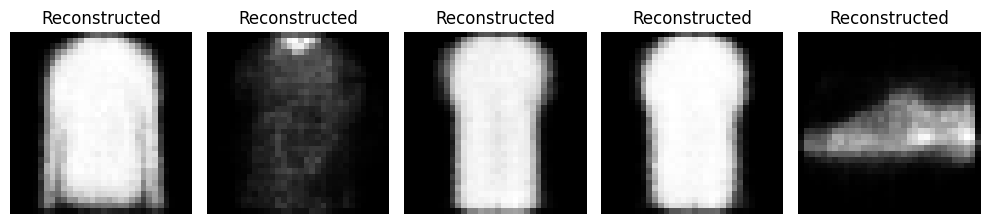

In [87]:
# Generate latent space samples for visualization
mins, maxs = np.min(embeddings, axis=0), np.max(embeddings, axis=0)
sample = torch.tensor(np.random.uniform(mins, maxs, size=(5, 2)), dtype=torch.float32)
print("Generated Latent Samples:\n", sample)
plot_reconstructions(autoencoder, sample, ex=False)

**Question:** Are there any objects not well reconstructed?

*Your answer:* Oui certains objets sont très peu nettes.

### Example for an ankle boot (provided in the exercise)

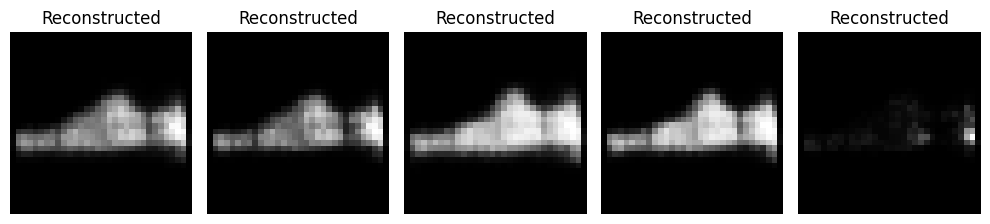

In [88]:
x_sample = torch.tensor([[0., 20], [0., 25], [-2., 20], [-2., 25], [5., 30]])
plot_reconstructions(autoencoder, x_sample, ex=False)

**Task:** Plot examples of **trousers**. (Complete the exercise below.)

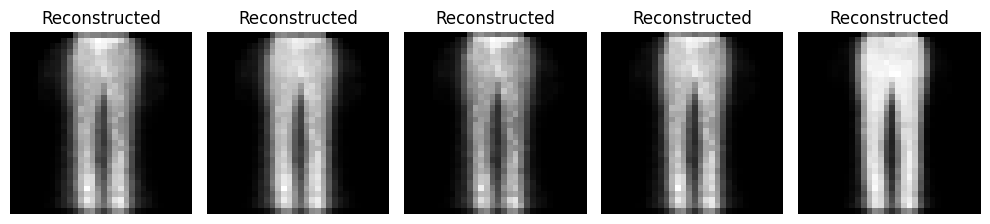

In [90]:
# TODO: Plot examples of trousers
x_sample = torch.tensor([[10., 8], [11., 8], [11., 9], [12., 9], [17., 10]])
plot_reconstructions(autoencoder, x_sample, ex=False)

### Save the model

In [91]:
torch.save(autoencoder.state_dict(), "VAmodel_state_dict.pth")